In [13]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [14]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

## Setup

In [15]:
V_width = 1
V_E_buffer = 0
E_width = 1
setup = (V_width,V_E_buffer,E_width)
N_trials = 10   # each trial will be a different group. Total variance will be measurement variance per group plus variance between groups.
N_neurons = 50      # size of group with "current" neuron included
total_neurons = 93

opt_params = {"track_quantities": False, "quiet": True, "iterations": 16}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}
critic_params = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}
samp_keep = 1

save_vars = {'N_neurons', 'opt_params', 'mi_measurement_params', 'N_trials', 'opt_params', 'V_width', 'V_E_buffer', 'E_width', 'critic_params'}

In [16]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=4)
print(f'current stimulus is {D.movname}')
mov_ind = D.mov_ind

current stimulus is opticflow


Sort neurons by self-prediction

In [17]:
D.reset()
D.trim(20)  # remove first 20 frames from each trial
V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)
pairwise_info = np.zeros(D.N)
for n in range(D.N):
    V.reset()
    E.reset()
    V.subset_features([n])
    E.subset_features([n])
    pairwise_info[n] = als.plugin_MI(V.X, E.X)
sort_by_info_inds = np.argsort(-pairwise_info)
save_vars.update({'sort_by_info_inds', 'pairwise_info'})

## Run test

In [18]:
experiment_dims = (total_neurons, N_trials)
averages_test_whole = np.zeros(experiment_dims)
stdevs_test_whole = np.zeros(experiment_dims)
averages_train_whole = np.zeros(experiment_dims)
stdevs_train_whole = np.zeros(experiment_dims)
averages_test_part = np.zeros(experiment_dims)
stdevs_test_part = np.zeros(experiment_dims)
averages_train_part = np.zeros(experiment_dims)
stdevs_train_part = np.zeros(experiment_dims)
neuron_inds_across_trials = np.zeros(experiment_dims, dtype=object)

    
for n in tqdm(range(total_neurons)):
    for trial in range(N_trials):   
        
        # make current neuron subset
        all_neurons_without_current = list(set(range(total_neurons)) - {n})
        neuron_inds_without_current = sample(all_neurons_without_current, k=N_neurons-1)
        neuron_inds_across_trials[n, trial] = neuron_inds_without_current
        # neuron_inds = list(set(neuron_inds_without_current) + {n})
        neuron_inds = neuron_inds_without_current + [n]

        critic_function_part = mds.SeparableCritic(**critic_params)
        critic_function_whole = mds.SeparableCritic(**critic_params)
        
        ## compute predictive information for 1:N-1
        D.reset()
        D.trim(20)
        D.subset_features(sort_by_info_inds)
        D.subset_features(neuron_inds_without_current)
        V, E = D.create_V_and_E_datasets(*setup)
        train_points, test_points = tools.generate_train_test_indices(V.P, 0.5)
        
        V.subset_points(train_points)
        E.subset_points(train_points)
        als.train_NCE(
            X=V.X,
            Y=E.X,
            critic_function=critic_function_part,
            **opt_params
        )

        # measure InfoNCE for train
        mi_train = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function_part, **mi_measurement_params
        )

        # measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(test_points)
        E.subset_points(test_points)
        mi_test = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function_part, **mi_measurement_params
        )
        
        averages_test_part[n, trial] = mi_test["mi"]
        stdevs_test_part[n, trial] = mi_test["mi_stdev"]
        averages_train_part[n, trial] = mi_train["mi"]
        stdevs_train_part[n, trial] = mi_train["mi_stdev"]


        ## compute predictive information for 1:N
        D.reset()
        D.trim(20)
        D.subset_features(sort_by_info_inds)
        D.subset_features(neuron_inds)
        V, E = D.create_V_and_E_datasets(*setup)
        
        V.subset_points(train_points)
        E.subset_points(train_points)
        als.train_NCE(
            X=V.X,
            Y=E.X,
            critic_function=critic_function_whole,
            **opt_params
        )

        # measure InfoNCE for train
        mi_train = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function_whole, **mi_measurement_params
        )

        # measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(test_points)
        E.subset_points(test_points)
        mi_test = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function_whole, **mi_measurement_params
        )
        
        averages_test_whole[n, trial] = mi_test["mi"]
        stdevs_test_whole[n, trial] = mi_test["mi_stdev"]
        averages_train_whole[n, trial] = mi_train["mi"]
        stdevs_train_whole[n, trial] = mi_train["mi_stdev"]


        
    

  0%|          | 0/93 [00:00<?, ?it/s]2024-07-06 15:02:07.641421: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-07-06 15:02:07.642087: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2256] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
100%|██████████| 93/93 [6:25:19<00:00, 248.60s/it]  


## Save

In [19]:
# select variables
critic_type = type(critic_function_part)
critic_config = critic_function_part.get_config()
save_vars.update({
    "averages_test_whole", 
    "stdevs_test_whole", 
    "averages_train_whole", 
    "stdevs_train_whole", 
    "averages_test_part", 
    "stdevs_test_part", 
    "averages_train_part", 
    "stdevs_train_part", 
    "critic_type",
    "critic_config"
})

local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [20]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, '', strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')

stim = D.movname
save_directory = os.path.join(cur_directory, 'saved', stim)
full_file_path = os.path.join(save_directory, f'self-prediction dependence, N={N_neurons}, tau={V_E_buffer+E_width}.dat')
# full_file_path = os.path.join(save_directory, 'test.dat')
# print(f"will save to {save_directory}")
print(f"will save to {full_file_path}")

will save to /home/adam/Documents/projects/retina-past-future-ib/analyses/synergy and scaling/saved/opticflow/self-prediction dependence, N=50, tau=1.dat


In [21]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)

## Reload and plot

In [3]:
stim = 'opticflow'
setup = (1,5,1)
N_neurons = 50
V_width, V_E_buffer, E_width = setup
tau = V_E_buffer + E_width

load_path = f'./saved/{stim}/self-prediction dependence, N={N_neurons}, tau={tau}.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)


In [4]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    full_stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, full_stdevs

In [5]:
# averages_test_whole, stdevs_test_whole = process_trials(data.averages_test_whole, data.stdevs_test_whole)
# averages_test_part, stdevs_test_part = process_trials(data.averages_test_part, data.stdevs_test_part)

averages_test_whole, stdevs_test_whole = data.averages_test_whole, data.stdevs_test_whole
averages_test_part, stdevs_test_part = data.averages_test_part, data.stdevs_test_part

single_info = data.pairwise_info

Text(0, 0.5, 'Information added to collective')

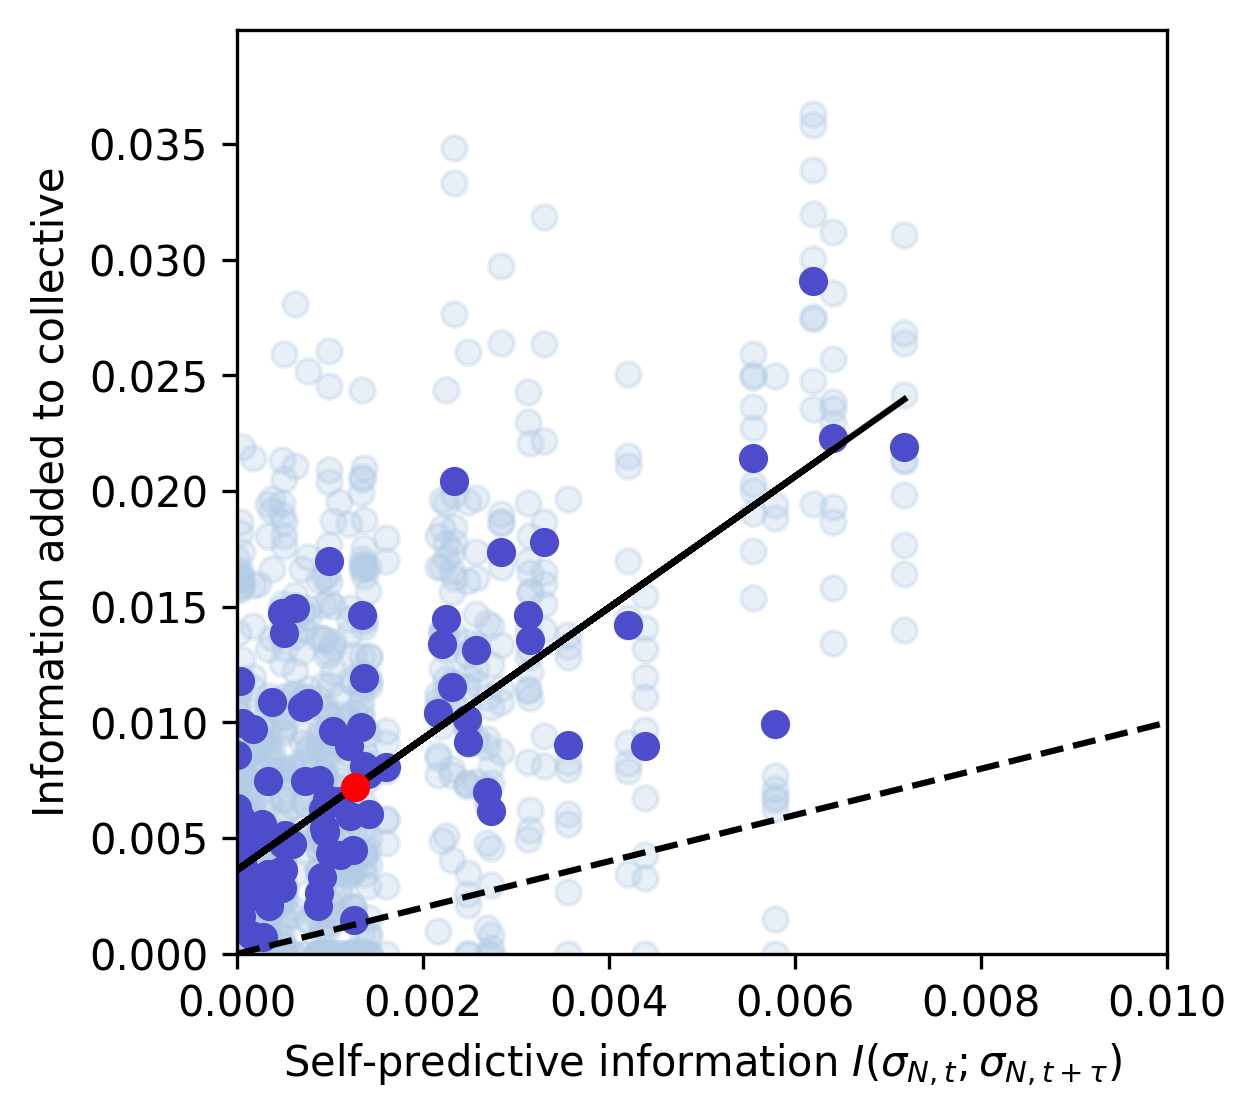

In [12]:
x = single_info / np.log(2)
y = (averages_test_whole - averages_test_part) / np.log(2)
y_avg = np.mean(y, axis=-1)
yerr = np.sqrt(stdevs_test_whole**2 + stdevs_test_part**2) / np.log(2)
y[y<0] = 0
fit = als.linear_regress(x, y_avg)

fig, ax = plt.subplots(figsize=[4,4], dpi=300)
max_x = np.max(x)
max_y = np.max(y)
max_both = max(max_x, max_y)
# ax.errorbar(x, y, yerr=yerr, marker='o', linestyle='')
ax.plot(x, y, marker='o', linestyle='', color=(0.7,0.8,0.9,0.3))
ax.plot(x, np.mean(y, axis=-1), marker='o', linestyle='', color=(0.3,0.3,0.8,1))
ax.plot(x, fit['fit'](x), color=(0,0,0))
ax.plot([0, max_both * 1.1], [0, max_both * 1.1], color='k', linestyle='--')
# ax.plot([0, max_x * 1.2 * 0.7], [0, max_y * 1.2])
mx = np.mean(x)
my = np.mean(y_avg)
# ax.plot([0, mx * 1.2], [0, my * 1.2])

ax.plot(mx, my, 'ro')
ax.set_xlim(0, max_both*1.1)
# ax.set_xlim(0, max_both*0.1)
ax.set_xlim(0, 0.01)
ax.set_ylim(0, max_both*1.1)
ax.set_xlabel(r'Self-predictive information $I(\sigma_{N,t}; \sigma_{N,t+\tau})$')
# ax.set_ylabel(r'$I(\sigma_{1:N,t}; \sigma_{1:N,t+\tau}) - I(\sigma_{1:N-1,t}; \sigma_{1:N-1,t+\tau})$')
ax.set_ylabel(r'Information added to collective')

In [11]:
fit['R_squared']

0.5158284214181124

In [35]:
yhat = fit['fit'](x)
ymean = np.mean(y, axis=-1)
1 - np.sum((ymean - yhat)**2) / np.sum((ymean - np.mean(y))**2)

0.5361052880115789